# 05 · U5 손 ROI 비용 — 깊이 → anchor → 질량별 η → MPPI 비용 합산

**학습 목표**

1. 공개된 실측 깊이 기록(236프레임)에서 `TargetMargin.update`의 ROI anchor 추출을 numpy로 재현하고, 실제 실행 로그의 anchor와 대조한다.
2. 가정 질량 → 환산질량 → 활성 거리 η 정책(p=0.5 / p=1)을 계산한다.
3. 로그에 남은 로봇 충돌 구(61개)로 손 관측면 간격과 손 비용을 다시 계산해 로그 값과 비교한다.
4. `TargetCostChannel`이 MPPI rollout의 `cost_fn`에 비용을 끼워 넣는 구조(CUDA graph capture 전 고정 슬롯)를 이해한다.
5. `feasible` 판정에 손 비용이 포함되지 않는다는 점을 정리하고 노션 U5 체크리스트에 답한다.

**노션에서 정리한 내용과의 연결 (U5)**

| 노션 기록 | 이 노트에서 확인 |
|---|---|
| ROI = 손 관측점 선택 영역, 기하 Primitive = 1 mm 장애물 | anchor 선택 규칙(yz 20 mm bin, 최소 12점, 중앙값 최근접)을 실제 데이터로 재현 |
| η: 0.6 kg → 25 mm, 2.3 kg → 42.87 mm(p=0.5) / 73.52 mm(p=1) | 식과 단위를 코드로 확인. R 조건 로그에도 η=25 mm 진단 비용이 기록되는 이유 |
| R step163에서 ROI 방식 평가 LOW/HIGH 비용 18,502.6 / 217,650.1 | 로그의 구·anchor로 근사 계산해 비교 |
| U5 체크리스트(삽입 위치, 변환식, feasible, 전 후보 침범, 관측 상실) | 10절에서 항목별로 답함 |

In [1]:
from common import *
plt = setup_plot()
import numpy as np
from scipy.spatial.transform import Rotation

meta = json.loads((TAPE / 'metadata.json').read_text())
frames = read_jsonl(TAPE / 'frames.jsonl')
cfg = json.loads((REPO / 'experiment/target.json').read_text())
K = np.array(meta['intrinsics'])
print('프레임 수', len(frames), '| map_step 범위', frames[0]['map_step'], '~', frames[-1]['map_step'], '| 총 시뮬레이션 step', meta['total_steps'])
print('intrinsics fx, fy, cx, cy =', K[0, 0].round(2), K[1, 1].round(2), K[0, 2].round(2), K[1, 2].round(2))
print('ROI bounds [m]:', cfg['manual_target_world_bounds_m'])
print('bin', cfg['patch_bin_yz_m'], 'm, 최소 점 수', cfg['min_points_per_bin'], ', 슬롯', cfg['proxy_capacity'], ', 패치 크기', cfg['nominal_point_proxy_dims_m'])

프레임 수 236 | map_step 범위 2 ~ 472 | 총 시뮬레이션 step 472
intrinsics fx, fy, cx, cy = 606.18 606.4 323.98 237.44
ROI bounds [m]: {'min': [0.42, -0.08, 0.32], 'max': [0.58, 0.08, 0.48]}
bin 0.02 m, 최소 점 수 12 , 슬롯 64 , 패치 크기 [0.001, 0.001, 0.001]


## 1. 카메라 → 로봇 좌표 변환

공개 입력은 기록 시 손 위치를 가상 로봇 경로에 맞추기 위해 카메라 pose를 평행이동한 **registered pose**를 쓴다(`hand_experiment.py:149-152`). 모든 조건에 같은 값이 적용된다.

pose 표기는 `[x, y, z, qw, qx, qy, qz]` (wxyz). `scipy.spatial.transform.Rotation.from_quat`는 **xyzw** 순서를 받으므로 `[*T[4:], T[3]]`로 바꿔 넣는다(코드 `hand_experiment.py:141`과 같은 방식).

In [2]:
reg = meta['hand_registration']
T = reg['registered_camera_to_robot_pose_wxyz']
R = Rotation.from_quat([*T[4:], T[3]]).as_matrix()
t = np.array(T[:3])
print('원래 pose      :', reg['original_camera_to_robot_pose_wxyz'])
print('registered pose:', np.round(T, 4).tolist())
print('평행이동 [m]   :', reg['translation_m'])
print('R (카메라 축 → 로봇 축):\n', R.round(3))
print('카메라 광축 z가 로봇 좌표에서 가리키는 방향:', (R @ [0, 0, 1]).round(3))

원래 pose      : [-0.05, 0, 0.45, 0.5, -0.5, 0.5, -0.5]
registered pose: [0.147, 0.0221, 0.3831, 0.5, -0.5, 0.5, -0.5]
평행이동 [m]   : [0.197, 0.0221, -0.0669]
R (카메라 축 → 로봇 축):
 [[ 0.  0.  1.]
 [-1.  0.  0.]
 [ 0. -1.  0.]]
카메라 광축 z가 로봇 좌표에서 가리키는 방향: [1. 0. 0.]


카메라 z(광축)가 로봇 +x 방향이다. 카메라는 로봇 쪽 앞에서 +x(손 쪽)를 보고 있고, 손바닥은 x≈0.55 m 근처에 놓인다.

## 2. 깊이 프레임과 ROI

역투영 (핀홀):

$$ \mathbf p_{cam} = \Big(\frac{(u-c_x) z}{f_x},\ \frac{(v-c_y) z}{f_y},\ z\Big),\qquad \mathbf p_{robot} = R\,\mathbf p_{cam} + t $$

코드에서는 `pc = [...] @ R.T + t` (행벡터 형태). 그 전에 영상 가장자리(위 24, 아래 24, 좌 32, 우 32 픽셀)를 0으로 지운다(`hand_experiment.py:244`).

map_step 164 | 유효 깊이 픽셀 63975 | ROI 안 점 26671


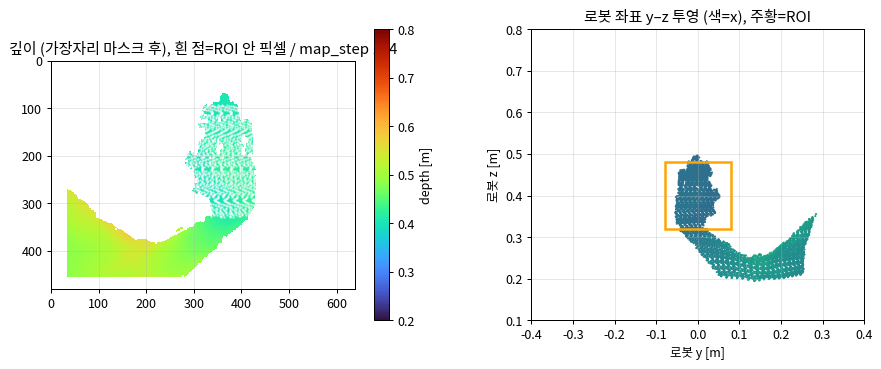

In [3]:
def load_depth(rec):
    d = np.load(TAPE / rec['file'])['depth_m'].copy()
    d[:24, :] = 0; d[456:, :] = 0; d[:, :32] = 0; d[:, 608:] = 0      # hand_experiment.py:244
    return d

LOW_B = np.array(cfg['manual_target_world_bounds_m']['min'])
HIGH_B = np.array(cfg['manual_target_world_bounds_m']['max'])

def backproject(d):
    ys, xs = np.nonzero(d > 0)
    z = d[ys, xs]
    pc = np.column_stack([(xs - K[0, 2]) * z / K[0, 0], (ys - K[1, 2]) * z / K[1, 1], z]) @ R.T + t
    return pc, ys, xs

rec = frames[81]
d = load_depth(rec)
pc, ys, xs = backproject(d)
in_roi = np.all((pc >= LOW_B) & (pc < HIGH_B), axis=1)
print('map_step', rec['map_step'], '| 유효 깊이 픽셀', len(pc), '| ROI 안 점', in_roi.sum())

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
im = axs[0].imshow(np.where(d > 0, d, np.nan), cmap='turbo', vmin=0.2, vmax=0.8)
axs[0].scatter(xs[in_roi][::20], ys[in_roi][::20], s=1, c='w', alpha=0.5)
plt.colorbar(im, ax=axs[0], label='depth [m]')
axs[0].set_title(f'깊이 (가장자리 마스크 후), 흰 점=ROI 안 픽셀 / map_step {rec["map_step"]}')
sub = pc[::15]
axs[1].scatter(sub[:, 1], sub[:, 2], s=0.5, c=sub[:, 0], cmap='viridis', vmin=0.3, vmax=1.0)
axs[1].add_patch(plt.Rectangle((LOW_B[1], LOW_B[2]), HIGH_B[1] - LOW_B[1], HIGH_B[2] - LOW_B[2], fill=False, ec='orange', lw=2))
axs[1].set_xlabel('로봇 y [m]'); axs[1].set_ylabel('로봇 z [m]'); axs[1].set_aspect('equal')
axs[1].set_xlim(-0.4, 0.4); axs[1].set_ylim(0.1, 0.8)
axs[1].set_title('로봇 좌표 y–z 투영 (색=x), 주황=ROI')
plt.show()

## 3. anchor 추출 재현 — `target_margin.py:19-35`

규칙:

1. ROI 안 점을 y–z 평면 20 mm bin으로 나눈다 (`group = bin_y*8 + bin_z`; ROI 높이 0.16 m / 0.02 = 8칸).
2. 점이 12개 미만인 bin은 버린다.
3. bin 점들의 성분별 중앙값에 **가장 가까운 실제 관측점**을 anchor로 고른다 (평균점이 아니라 실제 점).
4. nvblox `query_sdf`가 유효(`d > -99`)하고 `|d| ≤ 0.06 m`인 anchor만 남긴다. ← **여기서는 nvblox 지도가 없어 재현하지 못한다.**
5. 최대 64슬롯에 1 mm cuboid로 배치.

원본 코드를 먼저 보고, 같은 로직을 numpy로 옮긴다.

In [4]:
show_code(REPO / 'experiment/target_margin.py', 19, 35, width=170)

   19|     def update(self,data,mapper,R,t):
   20|         start=time.perf_counter();depth=data["depth"].numpy();K=data["intrinsics"].numpy();ys,xs=np.nonzero(depth>0);z=depth[ys,xs]
   21|         pc=np.column_stack([(xs-K[0,2])*z/K[0,0],(ys-K[1,2])*z/K[1,1],z])@R.T+t
   22|         mask=np.all((pc>=self.low)&(pc<self.high),axis=1);points=pc[mask].astype(np.float32)
   23|         self.points=points[::max(1,len(points)//2000)]
   24|         anchors=[]
   25|         if len(points):
   26|             bins=np.floor((points[:,1:]-self.low[1:])/self.cfg["patch_bin_yz_m"]).astype(int)
   27|             groups=bins[:,0]*8+bins[:,1]
   28|             for key in sorted(set(groups)):
   29|                 group=points[groups==key]
   30|                 if len(group)<self.cfg["min_points_per_bin"]:continue
   31|                 center=np.median(group,axis=0);anchor=group[np.argmin(np.linalg.norm(group-center,axis=1))];anchors.append(anchor)
   32|         anchors=np.asarray(anchors,np.f

In [5]:
def roi_points(d):
    pc, _, _ = backproject(d)
    return pc[np.all((pc >= LOW_B) & (pc < HIGH_B), axis=1)].astype(np.float32)

def candidate_anchors(points):
    """sdf 필터 이전 단계까지의 anchor 후보 (target_margin.py:24-32)."""
    bins = np.floor((points[:, 1:] - LOW_B[1:]) / cfg['patch_bin_yz_m']).astype(int)
    groups = bins[:, 0] * 8 + bins[:, 1]
    out = []
    for key in sorted(set(groups)):
        g = points[groups == key]
        if len(g) < cfg['min_points_per_bin']:
            continue
        center = np.median(g, axis=0)
        out.append(g[np.argmin(np.linalg.norm(g - center, axis=1))])
    return np.asarray(out, np.float32).reshape(-1, 3)

patches = {c: {r['step']: r for r in read_jsonl(EVIDENCE / c / 'patches-per-frame.jsonl')} for c in CONDITIONS}

rows = []
for rec in frames:
    pts = roi_points(load_depth(rec))
    cand = candidate_anchors(pts)
    logged = np.array(patches['LOW'][rec['map_step']]['anchors']).reshape(-1, 3)
    err = np.linalg.norm(cand[:, None] - logged[None], axis=-1).min(axis=0).max() if len(logged) else 0.0
    rows.append((rec['map_step'], len(pts), patches['LOW'][rec['map_step']]['roi_points'], len(cand), len(logged), err))
rows = np.array(rows)
print('ROI 점 수가 로그와 같은 프레임:', int((rows[:, 1] == rows[:, 2]).sum()), '/', len(rows))
print('로그 anchor가 모두 재현 후보 안에 있음(최대 오차 < 0.1 mm):', bool((rows[:, 5] < 1e-4).all()), '| 최대 오차 [m] =', rows[:, 5].max())
print('후보 수 범위', int(rows[:, 3].min()), '~', int(rows[:, 3].max()), '| sdf 필터 후(로그) 범위', int(rows[:, 4].min()), '~', int(rows[:, 4].max()))
same = all(patches['R'][s]['anchors'] == patches['LOW'][s]['anchors'] == patches['HIGH'][s]['anchors'] for s in patches['LOW'])
print('R/LOW/HIGH 세 조건의 anchor가 모든 프레임에서 동일:', same)

ROI 점 수가 로그와 같은 프레임: 236 / 236
로그 anchor가 모두 재현 후보 안에 있음(최대 오차 < 0.1 mm): True | 최대 오차 [m] = 7.001805755128379e-06
후보 수 범위 37 ~ 44 | sdf 필터 후(로그) 범위 10 ~ 35
R/LOW/HIGH 세 조건의 anchor가 모든 프레임에서 동일: True


결과 해석:

- ROI 점 수가 236프레임 모두 로그와 같다 → 마스크·intrinsics·registered pose·ROI 경계를 그대로 재현했다.
- 로그에 기록된 anchor는 전부 재현한 후보 집합 안에 있다(float32 반올림 수준 오차). 후보가 로그보다 많은 이유는 4단계 nvblox sdf 필터를 생략했기 때문이다.
- 세 조건의 anchor가 같다 → 지도 입력이 같으므로 손 표현은 조건 간 동일하고, 차이는 η와 비용 연결 여부뿐이다.

sdf 필터가 후보를 얼마나 걸러내는지 시간에 따라 본다.

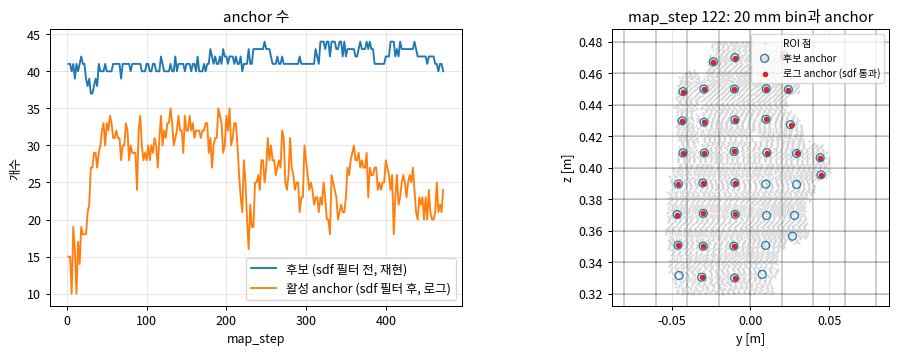

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(rows[:, 0], rows[:, 3], label='후보 (sdf 필터 전, 재현)')
axs[0].plot(rows[:, 0], rows[:, 4], label='활성 anchor (sdf 필터 후, 로그)')
axs[0].set_xlabel('map_step'); axs[0].set_ylabel('개수'); axs[0].legend(); axs[0].set_title('anchor 수')

rec = frames[60]
pts = roi_points(load_depth(rec)); cand = candidate_anchors(pts)
logged = np.array(patches['LOW'][rec['map_step']]['anchors'])
axs[1].scatter(pts[::5, 1], pts[::5, 2], s=0.5, c='lightgray', label='ROI 점')
axs[1].scatter(cand[:, 1], cand[:, 2], s=40, facecolors='none', edgecolors='tab:blue', label='후보 anchor')
axs[1].scatter(logged[:, 1], logged[:, 2], s=12, c='tab:red', label='로그 anchor (sdf 통과)')
for y in np.arange(LOW_B[1], HIGH_B[1] + 1e-9, 0.02):
    axs[1].axvline(y, color='k', lw=0.3)
for z in np.arange(LOW_B[2], HIGH_B[2] + 1e-9, 0.02):
    axs[1].axhline(z, color='k', lw=0.3)
axs[1].set_xlabel('y [m]'); axs[1].set_ylabel('z [m]'); axs[1].set_aspect('equal'); axs[1].legend(fontsize=8, loc='upper right')
axs[1].set_title(f'map_step {rec["map_step"]}: 20 mm bin과 anchor')
plt.show()

관찰한 것:

- 후보(필터 전)는 37–44개로 거의 일정한데, 활성 anchor(필터 후)는 10–35개로 크게 변한다.
- 처음 수십 프레임은 지도에 적분된 프레임이 적어 10–19개, step 100–200 근처에서 25–35개, step 약 210 이후로는 20–25개로 다시 줄었다.
- map_step 122 그림에서는 가장자리가 아니라 **손바닥 오른쪽 아래(y>0, z<0.40) 블록**의 후보가 빠졌다.

필터에서 빠진 이유(그 위치의 sdf가 −100인지, |d|>6 cm인지)는 공개 로그에 sdf 값이 없어 여기서는 가릴 수 없다. `hand_experiment.py --debug-anchor-sdf`를 켜면 후보별 sdf가 `anchor-sdf-debug.jsonl`에 기록된다. 확실한 것은 **필터를 통과한 anchor만 비용에 들어가므로 손 관측면 일부가 비용 표현에서 빠질 수 있다**는 점이다.

## 4. 질량 → η 정책

$$ \mu(m_h) = \frac{m_r m_h}{m_r + m_h},\quad m_r = 5\ \mathrm{kg}\ (\text{가정}) $$
$$ \eta(m_h; p) = 0.025 \left(\frac{\mu(m_h)}{\mu(0.6)}\right)^p\ [\mathrm m] $$

- `policy.py`는 p=0.5(제곱근)로 고정. 최종 HIGH는 `--eta-exponent 1.0`으로 같은 activation 텐서 값을 capture 전에 덮어쓴 민감도 설정(`hand_experiment.py:104-111`).
- 조건 이름 매핑: LOW → `ETA06`(0.6 kg), HIGH → `ETA23`(2.3 kg) (`hand_experiment.py:46`).
- 질량은 동역학 모델에 들어가지 않는다. η를 정하는 휴리스틱일 뿐이다.

    1| """Assumed masses mapped to activation distance; alpha is always one for added cost."""
    2| import math
    3| ROBOT_MASS_KG=5.0
    4| REFERENCE_HAND_MASS_KG=0.6
    5| REFERENCE_ETA_M=0.025
    6| HAND_MASSES={'ETA06':0.6,'ETA23':2.3}
    7| def reduced_mass(hand_mass):return ROBOT_MASS_KG*hand_mass/(ROBOT_MASS_KG+hand_mass)
    8| def mass_policy(condition):

조건          m_h[kg]   mu[kg]    p   eta[mm]
LOW             0.6   0.5357  0.5    25.000
LOW             0.6   0.5357  1.0    25.000
HIGH            2.3   1.5753  0.5    42.871
HIGH            2.3   1.5753  1.0    73.516
R 로그 eta_calculated_m = 0.025 | eta_gpu_m = 0.02500000037252903 | alpha = None | 식: 0.025*sqrt(mu(m_h)/mu(0.6))
LOW 로그 eta_calculated_m = 0.025 | eta_gpu_m = 0.02500000037252903 | alpha = 1.0 | 식: 0.025*sqrt(mu(m_h)/mu(0.6))
HIGH 로그 eta_calculated_m = 0.07351598173515982 | eta_gpu_m = 0.07351598143577576 | alpha = 1.0 | 식: 0.025*(mu(m_h)/mu(0.6))**1


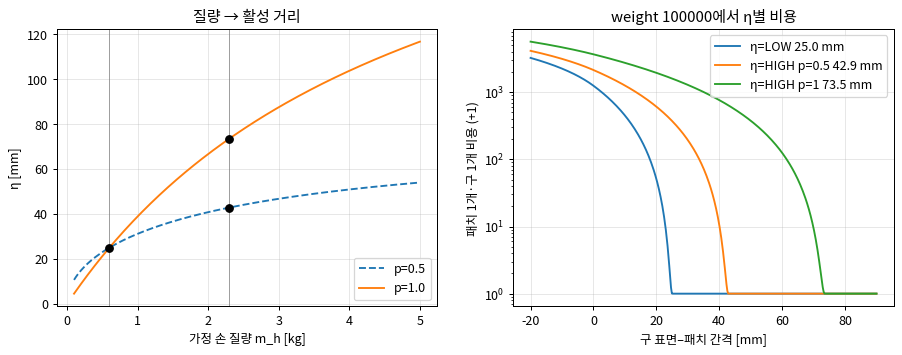

In [7]:
show_code(REPO / 'experiment/policy.py', 1, 8, width=140)
print()
print(f'{"조건":10s} {"m_h[kg]":>8s} {"mu[kg]":>8s} {"p":>4s} {"eta[mm]":>9s}')
for name, m in [('LOW', 0.6), ('HIGH', 2.3)]:
    for p in [0.5, 1.0]:
        print(f'{name:10s} {m:8.1f} {reduced_mass(m):8.4f} {p:4.1f} {1000*eta_policy(m, p):9.3f}')

for c in CONDITIONS:
    pol = json.loads((EVIDENCE / c / 'mass-policy.json').read_text())
    print(c, '로그 eta_calculated_m =', pol['eta_calculated_m'], '| eta_gpu_m =', pol.get('eta_gpu_m'), '| alpha =', pol.get('alpha'), '| 식:', pol['eta_formula'])

m = np.linspace(0.1, 5, 200)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for p, ls in [(0.5, '--'), (1.0, '-')]:
    axs[0].plot(m, 1000 * eta_policy(m, p), ls, label=f'p={p}')
for mh in [0.6, 2.3]:
    axs[0].axvline(mh, color='gray', lw=0.6)
axs[0].scatter([0.6, 2.3, 2.3], [25, 1000 * eta_policy(2.3, 0.5), 1000 * eta_policy(2.3, 1.0)], c='k', zorder=5)
axs[0].set_xlabel('가정 손 질량 m_h [kg]'); axs[0].set_ylabel('η [mm]'); axs[0].legend(); axs[0].set_title('질량 → 활성 거리')
gap = np.linspace(-0.02, 0.09, 400)
for name, eta in [('LOW 25.0', 0.025), ('HIGH p=0.5 42.9', eta_policy(2.3, 0.5)), ('HIGH p=1 73.5', eta_policy(2.3, 1.0))]:
    axs[1].semilogy(1000 * gap, eta_cost(gap, eta, 1e5) + 1, label=f'η={name} mm')
axs[1].set_xlabel('구 표면–패치 간격 [mm]'); axs[1].set_ylabel('패치 1개·구 1개 비용 (+1)'); axs[1].legend(); axs[1].set_title('weight 100000에서 η별 비용')
plt.show()

R 조건의 `mass-policy.json`에도 `eta_calculated_m = 0.025`가 있다. R에서도 `TargetCostChannel` 객체는 만들어지지만(`alpha=0`, rollout 훅 연결 안 함), 진단용 `target_diagnostic` 비용 객체가 η=25 mm로 현재 자세의 손 비용을 **기록만** 한다. 그래서 R 로그의 `target_cost_current`는 "R 자세를 LOW 방식으로 평가했다면"의 값이다.

## 5. 로봇 충돌 구와 간격 재계산

`evidence/*/robot-spheres.npz`의 `spheres`는 매 step 실제 관절 상태로 FK한 61개 구 `[x, y, z, r]`이다. 반지름이 buffer 포함인지 원래 구 정의와 비교해 확인한다.

In [8]:
sph = {c: np.load(EVIDENCE / c / 'robot-spheres.npz')['spheres'] for c in CONDITIONS}
mets = {c: read_jsonl(EVIDENCE / c / 'metrics.jsonl') for c in CONDITIONS}
print('spheres shape:', sph['R'].shape)

robot_cfg = load_yaml(CUROBO / 'src/curobo/content/configs/robot/franka.yml')['robot_cfg']['kinematics']
sphere_def = load_yaml(CUROBO / 'src/curobo/content/configs/robot' / robot_cfg['collision_spheres'])['collision_spheres']
link_names = robot_cfg['collision_link_names']
raw_r = np.array([s['radius'] for ln in link_names if ln in sphere_def for s in sphere_def[ln]])   # attached_object는 구 정의 없음(반지름<0 슬롯)
print('franka.yml collision_sphere_buffer =', robot_cfg['collision_sphere_buffer'], '(실험에서 0.02로 덮어씀, hand_experiment.py:90)')
print('정의된 구 수', len(raw_r), '| 로그 구 수', sph['R'].shape[1])
log_r = sph['R'][0, :, 3]
print('로그 반지름 - 원래 반지름: 고유값', np.unique(np.round(log_r - raw_r, 6)))

spheres shape: (472, 61, 4)
franka.yml collision_sphere_buffer = 0.004 (실험에서 0.02로 덮어씀, hand_experiment.py:90)
정의된 구 수 61 | 로그 구 수 61
로그 반지름 - 원래 반지름: 고유값 [0.02]


로그 반지름 = 원래 반지름 + 0.02 → **buffer 20 mm 포함**이다. 따라서 로그의 `original_surface_clearance_m`도 buffer 포함 간격이고, README 표의 "버퍼 제외" 값은 여기에 20 mm를 더한 것이다.

간격 정의 (`target_margin.py:51-54`, `TargetMargin.clearance`): ROI 점(약 2,000점으로 솎음)과 구 중심 거리에서 반지름을 뺀 최솟값. 각 step에서 쓰는 점은 그 step 이하의 가장 최근 map_step 프레임이다.

In [9]:
step_to_frame = {}
last = None
by_step = {r['map_step']: r for r in frames}
for s in range(1, meta['total_steps'] + 1):
    if s in by_step:
        last = by_step[s]
    step_to_frame[s] = last

cache = {}
def eval_points(rec):
    if rec['map_step'] not in cache:
        p = roi_points(load_depth(rec))
        cache[rec['map_step']] = p[::max(1, len(p) // 2000)]
    return cache[rec['map_step']]

clear = {}
for c in CONDITIONS:
    vals, logged = [], []
    for s in range(1, meta['total_steps'] + 1):
        rec = step_to_frame[s]
        logged.append(mets[c][s - 1]['original_surface_clearance_m'])
        if rec is None:
            vals.append(np.nan); continue
        S = sph[c][s - 1]; S = S[S[:, 3] > 0]
        P = eval_points(rec)
        vals.append((np.linalg.norm(P[:, None] - S[None, :, :3], axis=-1) - S[None, :, 3]).min())
    vals = np.array(vals); logged = np.array([np.nan if v is None else v for v in logged])
    clear[c] = vals
    ok = np.isfinite(vals) & np.isfinite(logged)
    i = np.nanargmin(vals)
    print(f'{c:4s} 재계산-로그 최대 차이 {np.abs(vals[ok]-logged[ok]).max()*1000:.4f} mm | 최소 간격(buffer 포함) {1000*vals[i]:7.2f} mm @ step {i+1} | buffer 제외 {1000*vals[i]+20:7.2f} mm')

R    재계산-로그 최대 차이 0.0000 mm | 최소 간격(buffer 포함)  -29.54 mm @ step 163 | buffer 제외   -9.54 mm
LOW  재계산-로그 최대 차이 0.0000 mm | 최소 간격(buffer 포함)  -11.20 mm @ step 169 | buffer 제외    8.80 mm
HIGH 재계산-로그 최대 차이 0.0000 mm | 최소 간격(buffer 포함)   40.43 mm @ step 165 | buffer 제외   60.43 mm


README 표의 최소 거리(R −29.54 / LOW −11.20 / HIGH +40.43 mm, buffer 포함)와 최소 시점(R 163 / LOW 169 / HIGH 165)이 그대로 나와야 한다. 단, 이 값은 A→B 구간이 아니라 **472 step 전체**의 최솟값이다. 구간을 A→B로 한정하면 같은 값인지 06 노트에서 확인한다.

## 6. 손 비용 근사 계산

cuRobo의 primitive 충돌 비용은 구마다 모든 활성 cuboid에 대해 `scale_eta_metric` 값을 **합산**하고 weight를 곱한다(`sphere_obb_kernel.cu:1061` `sphere_cache.w += eta`, `:1100` `max_dist += loc_grad.w`, `:1145` `weight * max_dist`). 그 뒤 구 61개를 합한다.

여기서는 1 mm cuboid를 점으로 보고 간격을 `|p − c| − r − 0.5 mm`로 근사한다. 그래서 정확히 같지는 않다. 비교 대상은 로그의 `target_cost_current` (현재 실제 자세 1개 시점, sweep/할인 없음)다.

R    비용>100인 step   9개 | 근사/로그 비율 중앙값 0.981 (범위 0.967~0.986)
LOW  비용>100인 step  20개 | 근사/로그 비율 중앙값 0.967 (범위 0.899~0.973)
HIGH 비용>100인 step  22개 | 근사/로그 비율 중앙값 0.955 (범위 0.918~0.970)

R step163 자세의 손 비용
  η=25 mm  : 근사    18252.1 | 로그 target_cost_current    18502.6 | 노션/CSV 18502.6
  η=73.5 mm: 근사   214752.2 | CSV roi_high_p1_cost 217650.1


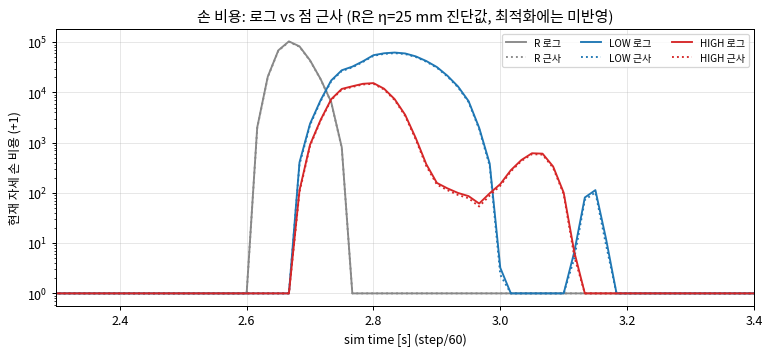

In [10]:
ETA = {'R': 0.025, 'LOW': 0.025, 'HIGH': eta_policy(2.3, 1.0)}

def hand_cost(S, anchors, eta, weight=1e5):
    S = S[S[:, 3] > 0]
    if len(anchors) == 0:
        return 0.0
    gap = np.linalg.norm(anchors[None] - S[:, None, :3], axis=-1) - S[:, None, 3] - 0.0005
    return float(eta_cost(gap, eta, weight).sum())

def anchors_at(c, s):
    ms = max(k for k in patches[c] if k <= s) if any(k <= s for k in patches[c]) else None
    return np.array(patches[c][ms]['anchors']).reshape(-1, 3) if ms else np.zeros((0, 3))

approx = {c: np.array([hand_cost(sph[c][s - 1], anchors_at(c, s), ETA[c]) for s in range(1, meta['total_steps'] + 1)]) for c in CONDITIONS}
logc = {c: np.array([m['target_cost_current'] for m in mets[c]]) for c in CONDITIONS}
for c in CONDITIONS:
    nz = logc[c] > 100
    ratio = approx[c][nz] / logc[c][nz]
    print(f'{c:4s} 비용>100인 step {nz.sum():3d}개 | 근사/로그 비율 중앙값 {np.median(ratio):.3f} (범위 {ratio.min():.3f}~{ratio.max():.3f})')

S163 = sph['R'][162]; A163 = anchors_at('R', 163)
print('\nR step163 자세의 손 비용')
print(f'  η=25 mm  : 근사 {hand_cost(S163, A163, 0.025):10.1f} | 로그 target_cost_current {logc["R"][162]:10.1f} | 노션/CSV 18502.6')
print(f'  η=73.5 mm: 근사 {hand_cost(S163, A163, ETA["HIGH"]):10.1f} | CSV roi_high_p1_cost 217650.1')

fig, ax = plt.subplots(figsize=(10, 4))
for c in CONDITIONS:
    ax.semilogy(np.arange(1, 473) / 60, logc[c] + 1, color=COLORS[c], label=f'{c} 로그')
    ax.semilogy(np.arange(1, 473) / 60, approx[c] + 1, ':', color=COLORS[c], label=f'{c} 근사')
ax.set_xlim(2.3, 3.4); ax.set_xlabel('sim time [s] (step/60)'); ax.set_ylabel('현재 자세 손 비용 (+1)')
ax.set_title('손 비용: 로그 vs 점 근사 (R은 η=25 mm 진단값, 최적화에는 미반영)'); ax.legend(ncol=3, fontsize=8)
plt.show()

- 점 근사는 로그보다 중앙값 기준 2–5%, 최대 10% 작게 나온다. 1 mm 큐브의 모서리 방향에서는 표면까지 거리가 0.5 mm보다 최대 √3배 짧아지는 것을 무시했기 때문이다. 경향과 크기는 맞는다.
- R step163의 η=25 mm 로그값 18,502.6은 노션에 적힌 "ROI 방식으로 별도 평가한 LOW 비용"과 같은 값이다. 즉 그 수치는 R 실행 중에 기록된 진단값이다.
- 이 값은 **현재 실제 자세 1개 시점**의 비용이다. MPPI가 비교하는 것은 400후보 × 30 step의 비용(시점 사이 sweep 포함)을 γ로 할인 합산한 값이므로, 이 그래프만으로 후보 선택을 설명하면 안 된다.
- HIGH가 비용 곡선이 가장 낮다: η가 커서 더 일찍 비용이 생기고, 그 결과 더 멀리 돌아가 실제 자세에서는 비용 구간에 덜 깊이 들어간다.

## 7. MPPI에 비용을 끼우는 구조 — `TargetCostChannel`

### 7.1 원본 코드

In [11]:
show_code(REPO / 'experiment/base_target_cost.py', 11, 46, width=170)

   11| class TargetCostChannel:
   12|     def __init__(self,mpc,ta,cfg,condition,session):
   13|         self.mpc,self.ta,self.session,self.condition=mpc,ta,session,condition
   14|         self.alpha=torch.tensor({'R':0.,'Z':0.,'L':1.,'H':2.}[condition],device=ta.device,dtype=ta.dtype)
   15|         self.names=['human_patch_%02d'%i for i in range(cfg['proxy_capacity'])]
   16|         self.world=WorldPrimitiveCollision(WorldCollisionConfig(tensor_args=ta,world_model=WorldConfig(cuboid=[Cuboid(name=n,pose=[10,0,0,1,0,0,0],dims=cfg['nominal_point ...
   17|         for n in self.names:self.world.enable_obstacle(n,False)
   18|         self.fixed_dims=np.array(cfg['nominal_point_proxy_dims_m']);self.enabled=0;self.optimizers=[];self.info=[]
   19|         for i,opt in enumerate(mpc.solver.optimizers):
   20|             assert not opt.cu_opt_init,'hook must precede optimizer capture'
   21|             env=opt.rollout_fn.primitive_collision_cost
   22|             kw={f.name:getattr(e

요점:

| 부분 | 하는 일 |
|---|---|
| `WorldPrimitiveCollision(... cuboid 64개, cache={'obb':64})` | 손 전용 충돌 세계. 슬롯 64개를 처음에 만들고 전부 비활성 |
| `PrimitiveCollisionCost(...)` | 환경 비용 설정(weight 100000, η 25 mm, sweep 등)을 복사하되 checker만 손 세계로 바꾼 비용 객체 |
| `assert not opt.cu_opt_init` | **CUDA graph capture 전**에만 연결 가능. capture 후에는 그래프가 기록된 커널만 재생하므로 파이썬 함수 교체가 반영되지 않는다 |
| `opt.rollout_fn.cost_fn = types.MethodType(hooked, ...)` | 실제 MPPI optimizer의 rollout 비용 함수를 `base + α·target`으로 교체 (R은 교체 안 함) |
| `_update_distribution` 감싸기 | 실제 optimizer가 받은 비용·가중치를 스냅샷으로 기록(검증용) |
| `pointers()` / `addresses` | α 텐서와 cuboid 캐시 텐서의 GPU 주소가 실행 내내 같은지 확인 |

`update(anchors)`는 슬롯 i < len(anchors)이면 pose를 바꾸고 enable, 나머지는 disable한다. **텐서를 새로 만들지 않고 같은 메모리 값만 바꾼다.** CUDA graph는 capture할 때의 메모리 주소를 그대로 읽으므로, 새 텐서를 할당하면 그래프는 옛 값을 계속 쓴다.

$$ C_{total}[b,t] = C_{existing}[b,t] + \alpha\, C_{hand}[b,t],\qquad \alpha = 1\ (\text{LOW/HIGH}) $$

### 7.2 같은 구조를 흉내 낸 작은 데모

GPU 없이 torch CPU 텐서로 "capture 시점에 주소를 기억하는 가짜 그래프"를 만들어, 제자리 갱신과 재할당의 차이를 본다.

In [12]:
import types, torch

class FakeRollout:
    def cost_fn(self, state):
        return state.pow(2).sum(-1)                    # 기존 비용 (목표 추종 등)

class FakeGraph:
    """capture 시점의 텐서 객체(=메모리)를 붙잡아 두고 재생만 하는 흉내."""
    def __init__(self, fn, *tensors):
        self.fn, self.tensors = fn, tensors
    def replay(self, state):
        return self.fn(state, *self.tensors)

slots = 4
patch_pos = torch.full((slots, 2), 10.0)              # 멀리 둔 비활성 슬롯
enabled = torch.zeros(slots)
alpha = torch.tensor(1.0)
eta = 0.5

rollout = FakeRollout()
original = rollout.cost_fn
def hooked(self, state, _old=original):
    base = _old(state)
    d = torch.cdist(state, patch_pos)                  # 후보 상태 vs 패치
    x = (eta - d).clamp(min=0)
    target = (enabled * torch.where(x > eta, x - eta / 2, x ** 2 / (2 * eta))).sum(-1)
    return base + alpha * target
rollout.cost_fn = types.MethodType(hooked, rollout)  # base_target_cost.py:36 과 같은 방식

graph = FakeGraph(lambda s, pp, en: rollout.cost_fn(s), patch_pos, enabled)
state = torch.tensor([[1.0, 0.0], [0.0, 1.0]])
print('패치 없음          :', graph.replay(state).tolist())

ptr = patch_pos.data_ptr()
patch_pos[0] = torch.tensor([1.2, 0.0]); enabled[0] = 1.0   # 제자리 갱신
print('제자리 갱신 후     :', graph.replay(state).tolist(), '| 주소 유지', patch_pos.data_ptr() == ptr)

new_pos = torch.tensor([[0.0, 1.2]] + [[10.0, 10.0]] * 3)    # 재할당 (잘못된 방법)
print('새 텐서를 만들었지만 그래프가 붙잡은 것은 옛 텐서 → 결과 불변:', graph.replay(state).tolist())

패치 없음          : [1.0, 1.0]
제자리 갱신 후     : [1.0899999141693115, 1.0] | 주소 유지 True
새 텐서를 만들었지만 그래프가 붙잡은 것은 옛 텐서 → 결과 불변: [1.0899999141693115, 1.0]


진짜 CUDA graph에서는 파이썬 함수조차 다시 호출되지 않고 기록된 GPU 커널이 같은 주소를 읽는다. 그래서 원본 코드는 (1) capture 전에 훅을 연결하고, (2) 64개 고정 슬롯을 미리 만든 뒤 pose·enable 값만 바꾸고, (3) 주소가 바뀌지 않았는지 매 갱신마다 `assert self.pointers()==self.addresses`로 확인한다. η 민감도 실험도 같은 이유로 `activation_distance.fill_(eta_p)` 후 `data_ptr()`가 같은지 확인한다(`hand_experiment.py:109`).

## 8. `feasible`과 손 비용

In [13]:
for c in CONDITIONS:
    feas = np.array([all(m['feasible']) for m in mets[c]])
    neg = np.array([(m['original_surface_clearance_m'] is not None and m['original_surface_clearance_m'] < 0) for m in mets[c]])
    hold = sum(m['hold_applied'] for m in mets[c])
    print(f'{c:4s} infeasible step {(~feas).sum():3d} | buffer 포함 간격<0 step {neg.sum():3d} (그중 feasible=True {int((neg & feas).sum())}) | hold-measured 적용 {hold}')
conn = json.loads((EVIDENCE / 'LOW' / 'cost-connection.json').read_text())
print('\ncost-connection.json:', conn['aux_and_safety_costs'])

R    infeasible step   0 | buffer 포함 간격<0 step   7 (그중 feasible=True 7) | hold-measured 적용 0
LOW  infeasible step   0 | buffer 포함 간격<0 step  11 (그중 feasible=True 11) | hold-measured 적용 0
HIGH infeasible step   0 | buffer 포함 간격<0 step   0 (그중 feasible=True 0) | hold-measured 적용 0

cost-connection.json: unchanged; reported constraints do not include target penalty


간격이 음수(buffer 포함 구가 관측면과 겹침)인 step에서도 `feasible=True`다. `cost-connection.json`도 "보고된 constraint에는 target penalty가 포함되지 않는다"고 기록한다. docs/diagnosis.md 정리:

> `feasible=true`는 설정된 반환 명령 상태의 제약 검사를 통과했다는 뜻이다. 실제 관측면과 비접촉, horizon 전체 비충돌, 미관측 공간 안전을 뜻하지 않는다.

손 비용은 순수한 soft cost다. 모든 후보가 손 영역을 침범하더라도 MPPI는 그중 상대적으로 비용이 낮은 후보(BEST)를 고른다. 별도 정지 로직은 `feasible=False`일 때만 동작한다(`mpc.step(..., max_attempts=2)` 재시도 후 `--failure-action hold-measured`이면 측정 위치 유지, `hand_experiment.py:298-314`).

## 9. 정정·확인 포인트

| 이전 이해 / 질문 | 확인한 것 |
|---|---|
| anchor = bin 점들의 평균 | 성분별 중앙값에 **가장 가까운 실제 관측점** |
| ROI 안 손 점은 모두 비용에 들어간다 | nvblox sdf 필터(관측됨 & 표면 6 cm 이내)를 통과한 anchor만, 최대 64개 |
| 로그 clearance = 구 표면과 손 사이 실제 거리 | buffer 20 mm 포함 구 ↔ 약 2,000점으로 솎은 ROI 관측점. 버퍼 제외 값은 +20 mm |
| R에는 손 비용 값이 없다 | 최적화에는 미반영(α=0, 훅 없음). 단 η=25 mm 진단값이 `target_cost_current`로 기록됨 |
| 18,502.6 / 217,650.1은 별도 재실험 결과 | R 실행 중 같은 자세를 η=25 / 73.5 mm로 평가한 진단값 (CSV `roi_low_cost`, `roi_high_p1_cost`) |
| 질량이 MPPI 동역학에 들어간다 | 질량은 η를 정하는 데만 쓰인다. rollout은 기구학 적분 |
| 손 비용이 크면 infeasible 처리된다 | feasible에 손 비용은 포함되지 않는다 |

## 10. 노션 U5 체크리스트 답변

| 항목 | 답 |
|---|---|
| ROI 추가 비용의 삽입 위치와 기존 환경 비용과의 결합 | 실제 `ParallelMPPI` optimizer의 `rollout_fn.cost_fn`을 capture 전에 교체. `total = base + α·target`, α=1. 기존 nvblox 환경 비용·자체충돌·목표·bound·stop은 그대로 (`base_target_cost.py:31-36`) |
| 0.6 / 2.3 kg → 25 / 42.87 mm 변환식·가정·단위 | $\eta = 0.025\,(\mu(m_h)/\mu(0.6))^{p}$ [m], $m_r$=5 kg 가정, p=0.5 → 42.87 mm, 최종 p=1 → 73.52 mm (4절) |
| ROI 비용이 feasible 판정에 포함되는가 | 포함되지 않음 (8절) |
| 모든 particle이 ROI를 침범하면 | soft cost이므로 그중 비용이 낮은 BEST 후보가 명령이 된다. 재시도·hold는 feasible=False일 때만 |
| ROI 관측 상실 시 비용 비활성화와 로그 | anchor가 없는 슬롯은 `enable_obstacle(n, False)` → 비용 0. 프레임마다 `patches-per-frame.jsonl`에 개수·상태(`observed_target` / `no_supported_target_observation`) 기록. 관측 누락과 실제 제거는 구분하지 않는다 (docs/method.md) |

## 복습 질문

<details><summary>1. 재현한 anchor 후보가 로그 anchor보다 많은 이유는?</summary>

로그 anchor는 nvblox `query_sdf`로 "관측된 표면 근처(|d|≤6 cm, d>−99)"인 후보만 남긴 결과다. 노트북에는 nvblox 지도가 없어 이 필터를 생략했다.
</details>

<details><summary>2. 활성화 텐서를 `fill_`로 바꾸고 `data_ptr()`를 확인하는 이유는?</summary>

CUDA graph는 capture 때의 메모리 주소를 재생한다. 새 텐서를 할당하면 그래프는 옛 메모리를 계속 읽어 바꾼 η가 반영되지 않는다. 제자리 갱신과 주소 확인으로 이를 막는다.
</details>

<details><summary>3. R 로그에 `target_cost_current`가 있는데도 R을 "추가 손 비용 없음"이라고 부르는 이유는?</summary>

R은 rollout 비용 함수를 교체하지 않는다(α=0). 기록된 값은 진단용 별도 비용 객체로 현재 자세를 평가한 숫자일 뿐 MPPI 후보 비용에 더해지지 않는다.
</details>

<details><summary>4. HIGH의 실제 자세 손 비용이 LOW보다 낮게 기록되는 것이 모순이 아닌 이유는?</summary>

η가 크면 같은 간격에서 비용이 더 크고 더 먼 거리에서 시작된다. MPPI는 그 비용을 피하는 후보를 골라 더 멀리 돌아갔고, 실제 실행된 자세는 비용 구간에 덜 들어갔다. 비용 함수의 크기와 실행 결과의 비용은 다른 양이다.
</details>

<details><summary>5. clearance가 음수인데 물리 접촉이 증명되지 않는 이유는?</summary>

간격은 buffer 20 mm를 포함한 근사 구와 카메라에 보인 손 앞면 점 사이 값이다. 실제 Franka mesh, 손 뒷면, 깊이 경계 노이즈는 반영되지 않는다.
</details>

---
**다음:** `06_U6_experiment_analysis.ipynb` — evidence 로그로 R/LOW/HIGH의 이격·경로·도달 시간·상태 입력 차이를 분석한다.